In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.pyplot import subplots

In [2]:
Suits = ["H", "D", "C", "S"]
Ranks = ["J", "Q", "K", "A"]
Ranks2 = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]

class Card():
    def __init__(self, suit, rank, hot, fulldeck = False):
        self.suit = suit
        self.rank = rank
        self.name = rank+suit

        if fulldeck == False:
            self.hot = np.zeros(16)
            self.hot[hot] = 1
        else:
            self.hot = np.zeros(52)
            self.hot[hot] = 1

        try:
            self.value = int(rank)
        except:
            self.value = 11+Ranks.index(rank)

def NewDeck(fulldeck = False):

    if fulldeck == False:
        Ranks_ = Ranks
    else:
        Ranks_ = Ranks2

    Deck = list(np.random.permutation([Card(suit, rank, hot) for hot, (suit, rank) in enumerate(( (suit, rank) for rank in Ranks_ for suit in Suits))]))

    return Deck

In [3]:
class ToM0(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_cards=16):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, num_cards)

    def forward(self, x, hidden=None):
        output, hidden = self.gru(x, hidden)

        # Output from the current timestep
        logits = self.fc(output[:, -1, :])

        return logits, hidden

In [4]:
class Player():
    def __init__(self, hand, name):
        self.hand = hand
        self.tricks_won = 0
        self.games_won = 0
        self.name = name

class Spades():
    def __init__(self, manual = True, randomagents = False, model = None, number_games = 100,
                  learning = True, modelagents = False, opponentmodel = False, opponent_learning = False,
                  tom2_model = False):
        self.currentplayernumber = None
        self.table = None
        self.tablenamed = None
        self.manual = manual
        self.stop = False
        self.randomagents = randomagents
        self.stopcheck = "yes"
        self.modelagents = modelagents
        self.opponentmodel = None
        self.opponent_prediction_model = opponentmodel
        self.opponent_learning = opponent_learning
        self.counter = 0
        self.correctcounter = 0
        self.player0_played = 0
        self.tom2ready = False
        self.tom2_model = tom2_model
        self.tom2_pending_logits = None
        self.tom2_2pending_logits = None
        self.backup_hidden = None

        if modelagents:
            self.opponentmodel = ToM0(52)
            self.opponentmodel.load_state_dict(torch.load("spades_model.pth"))
            self.opponentmodel.eval()
            for param in self.opponentmodel.parameters():
                param.requires_grad = False

        if model:
            self.model = model
            self.optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
            self.number_games = number_games
            self.learning = learning
            #self.model.load_state_dict(torch.load("spades_model.pth"))
            self.model.eval()
            self.winrate = []

        if opponentmodel:
            self.opponent_prediction_model = ToM0(52)
            self.opponent_optimizer = torch.optim.Adam(self.opponent_prediction_model.parameters(), lr=0.001)
            if self.opponent_learning == False:
                self.opponent_prediction_model.load_state_dict(torch.load("opponent_prediction_model.pth"))
                self.opponent_prediction_model.eval()

        if tom2_model:
            self.tom2_2model = ToM0(36)
            self.tom2_2_optimizer = torch.optim.Adam(self.tom2_2model.parameters(), lr=0.001)
            self.tom2_2_loss = torch.nn.CrossEntropyLoss()

            self.tom2_model = ToM0(68)
            self.tom2_optimizer = torch.optim.Adam(self.tom2_model.parameters(), lr=0.001)
            self.tom2_loss = torch.nn.CrossEntropyLoss()

            self.backup_model = ToM0(52)
            self.backup_model.load_state_dict(torch.load("spades_model.pth"))
            self.backup_model.eval()

            for param in self.backup_model.parameters():
                param.requires_grad = False


    def GameStart(self):
        count = 0
        # print(f"GAME {count + 1}")
        Deck = NewDeck()
        self.players = [Player(Deck[i*4:(i+1)*4], "player " + str(i+1)) for i in range(4)]

        while self.stop == False:
            randomizedinitialization = np.random.randint(4)
            self.playerorder = (np.array([0,1,2,3])+randomizedinitialization)%4
            self.hot_position = np.where(self.playerorder == 0, 1, 0)


            if self.model:
                self.hidden = None
                self.reward = []
                self.logprob = []

            if self.opponentmodel:
                self.opponenthidden = [None, None, None]

            if self.opponent_prediction_model:
                self.prediction_hidden = [None, None, None]

            if self.tom2_model:
                self.tom2_hidden = None
                self.tom2_2_hidden = None
                self.backup_hidden = None

            self.hothistory = np.zeros(len(Deck))

            for players in self.players:
                players.tricks_won = 0

            for _ in range(4):
                self.table = []
                self.tablenamed = []
                self.tablehot = np.zeros(len(Deck))
                self.predicted_logit_save = []
                self.tom2_pending_logits = None
                self.tom2_2pending_logits = None
                self.usedbackup = False

                for i in range(4):
                    self.currentplayernumber = self.playerorder[i]
                    self.Step()

                self.player0_played = 0
                self.hothistory += self.tablehot
                winner = self.CheckTrickWin()

                # print("Table: ", self.tablenamed)
                # print("The play order was: ", np.array(self.playerorder)+1)
                # print(f"{self.players[winner].name} has won this trick")

                self.players[winner].tricks_won += 1

                if winner == 0:
                    self.reward.append(1)

                else:
                    self.reward.append(0)

                self.currentplayernumber = winner
                self.playerorder = (np.array([0,1,2,3])+self.currentplayernumber)%4
                self.hot_position = np.where(self.playerorder == 0, 1, 0)
                # print("\n---------------------------------\n")

            count += 1

            winning_player = max(range(4), key=lambda i: self.players[i].tricks_won) + 1
            # print(f"winning_player is Player {winning_player} \n")

            max_trick = max([self.players[i].tricks_won for i in range(4)])
            winners_list = [i for i in range(4) if self.players[i].tricks_won == max_trick]
            for i in winners_list:
                self.players[i].games_won += 1/len(winners_list) 

            if 0 in winners_list:
                self.reward = [1/len(winners_list) for i in self.reward]
            else:
                self.reward = [-1 for i in self.reward]

            if self.model and self.learning:
                loss = 0
                trained_decisions = 0

                for prob, reward in zip(self.logprob, self.reward):
                    if prob is not None:
                        loss += -prob * reward
                        trained_decisions += 1

                if trained_decisions > 0:
                    self.optimizer.zero_grad()
                    loss.backward()
                    self.optimizer.step()

            if self.manual == True:
                self.stopcheck = input("Continue the game yes/no: ")

            if count%100 == 0 or (count%10 == 0 and count<100):
                winrate = self.players[0].games_won / count
                self.winrate.append(winrate)
                print(f"Winrate after {count} Games is {winrate*100:2f}%")
                if self.opponentmodel and self.opponent_learning:
                    print(f"The accuracy of the opponent predictions is {self.correctcounter/self.counter*100:.2f}%")

            elif count >= self.number_games:
                self.stopcheck = "no"

            if self.stopcheck == "no":
                self.stop = True
                # print("\n---------------------------------\n")
                # for player in self.players:
                    # print(f"{player.name} has won {player.games_won} games\n")
            else:
                Deck = NewDeck()
                for i, player in enumerate(self.players):
                    player.hand = Deck[i*4:(i+1)*4]
                # print(f"GAME {count + 1}")
                # print("\n---------------------------------\n")

        

    def Step(self):

        if self.currentplayernumber == 0:
            self.player0_played = 1

        if np.where(self.playerorder == 0)[0][0] < 2 and self.tom2_model:
            self.tom2ready = True
        else:
            self.tom2ready = False

        self.currentplayer = self.players[self.currentplayernumber]
        self.legalmoves = self.LegalMoves()
        legalenum = enumerate(self.legalmoves)
        # print("Table:", self.tablenamed)

        if self.opponent_prediction_model and self.currentplayernumber != 0 and self.opponent_learning == True:
            hothand = np.zeros(len(self.tablehot))

            for card in self.players[0].hand:
                hothand += card.hot

            opponent_position_hot = np.zeros(4)
            opponent_position_hot[self.currentplayernumber] = 1
            input_hotencoded = np.concatenate([hothand, self.tablehot, self.hothistory, opponent_position_hot])
            x = torch.tensor(input_hotencoded, dtype=torch.float32)
            x = x.view(1, 1, -1)
            prediction_logits, self.prediction_hidden[self.currentplayernumber - 1] = self.opponent_prediction_model(x, self.prediction_hidden[self.currentplayernumber - 1])
            mask = torch.where(torch.tensor(self.hothistory+self.tablehot+hothand) == 0,  torch.tensor(0.0), torch.tensor(float("-inf")))
            prediction_logits = prediction_logits + mask


        if self.tom2ready and self.currentplayernumber == 0:
            hothand = np.zeros(len(self.tablehot))

            for card in self.players[0].hand:
                hothand += card.hot     

            opponent_position_hot = np.zeros(4)
            opponent_position_hot[self.currentplayernumber] = 1
            public_input_hotencoded = np.concatenate([self.tablehot, self.hothistory, opponent_position_hot])
            x = torch.tensor(public_input_hotencoded, dtype=torch.float32)
            x = x.view(1, 1, -1)
            prediction_logits_tom2_2, self.tom2_2_hidden = self.tom2_2model(x, self.tom2_2_hidden)
            self.tom2_2_hidden = self.tom2_2_hidden.detach()
            mask = torch.where(torch.tensor(self.hothistory+self.tablehot) == 0,  torch.tensor(0.0), torch.tensor(float("-inf")))
            prediction_logits_tom2_2 = prediction_logits_tom2_2 + mask
            self.tom2_2pending_logits = prediction_logits_tom2_2
            prediction_probs_tom2_2 = torch.softmax(prediction_logits_tom2_2, dim=-1)
            prediction_logits_tom2_2 = prediction_probs_tom2_2.detach().cpu().numpy().reshape(-1)

            input_hotencoded = np.concatenate([hothand, self.tablehot, self.hothistory, prediction_logits_tom2_2, opponent_position_hot])
            x = torch.tensor(input_hotencoded, dtype=torch.float32)
            x = x.view(1, 1, -1)
            prediction_logits_tom2, self.tom2_hidden = self.tom2_model(x, self.tom2_hidden)
            self.tom2_hidden = self.tom2_hidden.detach()
            mask = torch.where(torch.tensor(self.hothistory+self.tablehot+hothand) == 0,  torch.tensor(0.0), torch.tensor(float("-inf")))
            prediction_logits_tom2 = prediction_logits_tom2 + mask
            self.tom2_pending_logits = prediction_logits_tom2
            prediction_probs_tom2 = torch.softmax(prediction_logits_tom2, dim=-1)
            prediction_logits_tom2 = prediction_probs_tom2.detach().cpu().numpy().reshape(-1)


        if self.player0_played == 0 and self.opponent_learning == False and self.opponent_prediction_model:
            hothand = np.zeros(len(self.tablehot))

            for card in self.players[0].hand:
                hothand += card.hot

            opponent_position_hot = np.zeros(4)
            opponent_position_hot[self.currentplayernumber] = 1
            input_hotencoded = np.concatenate([hothand, self.tablehot, self.hothistory, opponent_position_hot])
            x = torch.tensor(input_hotencoded, dtype=torch.float32)
            x = x.view(1, 1, -1)
            with torch.no_grad():
                prediction_logits, self.prediction_hidden[self.currentplayernumber - 1] = self.opponent_prediction_model(x, self.prediction_hidden[self.currentplayernumber - 1])
            self.predicted_logit_save.append(np.zeros_like(self.hothistory))

        if self.currentplayernumber == 0 and self.opponent_learning == False and self.opponent_prediction_model:
            index_player0 = np.where(self.playerorder == 0)[0][0]
            hothand = np.zeros(len(self.tablehot))

            for card in self.players[0].hand:
                hothand += card.hot


            if index_player0 != 3:
                for i in range(3-index_player0):
                    opponent_position_hot = np.zeros(4)
                    opponent_position_hot[i+1] = 1
                    input_hotencoded = np.concatenate([hothand, self.tablehot, self.hothistory, opponent_position_hot])
                    x = torch.tensor(input_hotencoded, dtype=torch.float32)
                    x = x.view(1, 1, -1)

                    with torch.no_grad():
                        prediction_logits, self.prediction_hidden[i] = self.opponent_prediction_model(x, self.prediction_hidden[i])

                    mask = torch.where(torch.tensor(self.hothistory+self.tablehot+hothand) == 0,  torch.tensor(0.0), torch.tensor(float("-inf")))
                    prediction_logits = prediction_logits + mask
                    prediction_probs = torch.softmax(prediction_logits, dim=-1)
                    self.predicted_logit_save.append(prediction_probs.squeeze(0).cpu().numpy())



        if self.randomagents == True and self.currentplayernumber != 0:
            choice = np.random.randint(len(self.legalmoves))
            self.PlayCard(choice)
            return

        # else:
        #     # print("Legal actions are:")
        #     # for i,c in legalenum:
        #     #     print(f"{i+1}: {c.name}")
        #     # print()

        if self.manual == True:
            choice = int(input("Enter the number of the card: ")) - 1
            self.PlayCard(choice)
            return

        if self.manual == False:
            hothand = np.zeros(len(self.tablehot))
            self.legalhot = np.zeros_like(self.hothistory)
            self.legalhotlist = []
            for card in self.legalmoves:
                self.legalhot += card.hot
                self.legalhotlist.append(list(card.hot).index(1))
                
            # print(self.legalhot)
            # print(self.legalhotlist)

            for card in self.currentplayer.hand:
                hothand += card.hot

            input_hotencoded = np.concatenate([hothand, self.tablehot, self.hothistory, self.hot_position])

            if self.opponent_prediction_model and self.opponent_learning == False and self.currentplayernumber == 0:
                logit_save_flatten = np.array(self.predicted_logit_save).flatten()
                input_hotencoded = np.concatenate([input_hotencoded, logit_save_flatten])

            if self.tom2ready and self.currentplayernumber == 0:
                input_hotencoded = np.concatenate([input_hotencoded, prediction_logits_tom2])

            x = torch.tensor(input_hotencoded, dtype=torch.float32)
            x = x.view(1, 1, -1)

            if self.currentplayernumber == 0 and not self.tom2_model:
                logits, self.hidden = self.model(x, self.hidden)

            elif self.currentplayernumber == 0 and self.tom2ready:
                logits, self.hidden = self.model(x, self.hidden)

            elif self.currentplayernumber == 0 and self.tom2_model and not self.tom2ready:
                logits, self.backup_hidden = self.backup_model(x, self.backup_hidden)
                self.backup_hidden = self.backup_hidden.detach()
                self.usedbackup = True
                

            elif self.opponentmodel:
                with torch.no_grad():
                    logits, self.opponenthidden[self.currentplayernumber - 1] = self.opponentmodel(x, self.opponenthidden[self.currentplayernumber - 1])

            mask = torch.where(torch.tensor(self.legalhot) == 0, torch.tensor(float("-inf")), torch.tensor(0.0))
            logits = logits + mask
            # print(logits)
            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            if self.currentplayernumber == 0:
                if not self.usedbackup:
                    log_prob = distribution.log_prob(action)
                    self.logprob.append(log_prob)
                else:
                    self.logprob.append(None)

            # print(action.item())
            choice = self.legalhotlist.index(action.item())

            if self.opponent_prediction_model and self.currentplayernumber != 0 and self.opponent_learning == True:
                loss = F.cross_entropy(prediction_logits, action)
                self.opponent_optimizer.zero_grad()
                loss.backward()
                self.opponent_optimizer.step()
                predicted_card = prediction_logits.argmax(dim=-1).item()

                opponent_index = self.currentplayernumber - 1
                self.prediction_hidden[opponent_index] = \
                    self.prediction_hidden[opponent_index].detach()

                correct = predicted_card == action.item()
                self.counter += 1
                self.correctcounter += int(correct)

            # Train both ToM2 models when the predicted opponent actually acts
            if self.tom2ready and self.currentplayernumber == 2:
                loss_2_2 = F.cross_entropy(self.tom2_2pending_logits, action)
                self.tom2_2_optimizer.zero_grad()
                loss_2_2.backward()
                self.tom2_2_optimizer.step()
                

            if self.tom2ready and self.currentplayernumber == 1:
                loss_2 = F.cross_entropy(self.tom2_pending_logits, action)
                self.tom2_optimizer.zero_grad()
                loss_2.backward()
                self.tom2_optimizer.step()

            # print(choice)
            self.PlayCard(choice)
            return


    def LegalMoves(self):
        if self.table == []:
            return self.currentplayer.hand
        else:
            availablesuits = [self.currentplayer.hand[i].suit for i in range(len(self.currentplayer.hand))]
            if self.leadingsuit in availablesuits:
                indices = [i for i, card in enumerate(availablesuits) if self.leadingsuit == card]
                return [self.currentplayer.hand[i] for i in indices]
            else:
                return self.currentplayer.hand

    def PlayCard(self, choice):
        card = self.legalmoves[choice]
        if self.table == []:
            self.leadingsuit = card.suit
        self.table.append(card)
        self.tablenamed.append(card.name)
        self.tablehot += card.hot
        self.currentplayer.hand.remove(card)

    def CheckTrickWin(self):
        playedsuits = [card.suit for card in self.table]
        if "S" in playedsuits:
            winner = self.playerorder[max([(i, self.table[i]) for i, s in enumerate(playedsuits) if s == "S"], key=lambda tple: tple[1].value)[0]]
            return winner
        else:
            winner = self.playerorder[max([(i, self.table[i]) for i, s in enumerate(playedsuits) if s == self.leadingsuit], key=lambda tple: tple[1].value)[0]]
            return winner

In [5]:
game = Spades(randomagents=False, manual=False, model=ToM0(68), number_games=300000, learning=True,
              modelagents=True, opponentmodel=False, opponent_learning=False, tom2_model=True)
game.GameStart()

Winrate after 10 Games is 27.500000%
Winrate after 20 Games is 28.750000%
Winrate after 30 Games is 25.833333%
Winrate after 40 Games is 28.125000%
Winrate after 50 Games is 28.000000%
Winrate after 60 Games is 28.750000%
Winrate after 70 Games is 27.500000%
Winrate after 80 Games is 26.562500%
Winrate after 90 Games is 28.055556%
Winrate after 100 Games is 26.750000%
Winrate after 200 Games is 27.625000%
Winrate after 300 Games is 25.166667%
Winrate after 400 Games is 24.062500%
Winrate after 500 Games is 25.750000%
Winrate after 600 Games is 26.333333%
Winrate after 700 Games is 26.571429%
Winrate after 800 Games is 27.093750%
Winrate after 900 Games is 27.888889%
Winrate after 1000 Games is 28.150000%
Winrate after 1100 Games is 27.909091%
Winrate after 1200 Games is 27.625000%
Winrate after 1300 Games is 27.653846%
Winrate after 1400 Games is 28.017857%
Winrate after 1500 Games is 28.233333%
Winrate after 1600 Games is 27.890625%
Winrate after 1700 Games is 27.926471%
Winrate after

In [8]:
torch.save(game.tom2_model.state_dict(), "spades_model_ToM2_1.pth")

In [32]:
torch.save(game.opponent_prediction_model.state_dict(), "opponent_prediction_model.pth")

Average winrate of last 100 games is 33.65%


C:\Users\diego\AppData\Local\Temp\ipykernel_21284\3568007342.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


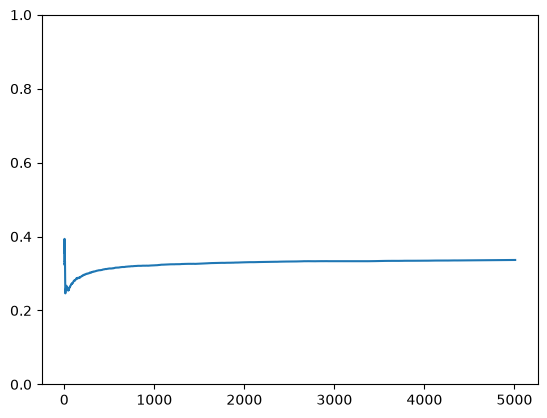

In [20]:
winrate = game.winrate
fig, ax = subplots(1,1)
ax.plot(range(len(winrate)), winrate)
ax.set_ylim(0,1)
fig.show()
print(f"Average winrate of last 100 games is {np.mean(winrate[-100:])*100:.2f}%")

Average winrate of last 100 games is 33.85%


C:\Users\diego\AppData\Local\Temp\ipykernel_21284\3568007342.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


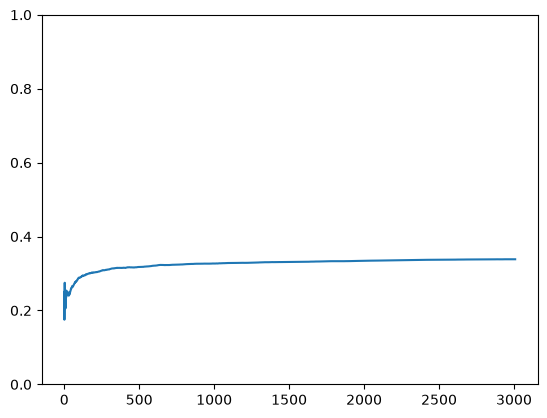

: 

In [ ]:
winrate = game.winrate
fig, ax = subplots(1,1)
ax.plot(range(len(winrate)), winrate)
ax.set_ylim(0,1)
fig.show()
print(f"Average winrate of last 100 games is {np.mean(winrate[-100:])*100:.2f}%")

In [34]:
[]+[1,4,2,76]

[1, 4, 2, 76]